# What is adaptive optics? Explainer movies with HCIPy

This notebook simulates one closed-loop adaptive-optics (AO) system end to end and writes
a few short movies, one per building block, to explain what AO does:

1. **Distorted wavefront** – the turbulent atmosphere above an 8 m telescope (one layer, 20 m/s wind, 0.7" seeing).
2. **Wavefront sensor** – what the pyramid wavefront sensor (36 pixels across the pupil) sees, and the slopes derived from it.
3. **Deformable mirror** – the shape the 24 x 24 actuator deformable mirror takes to cancel the atmosphere.
4. **Corrected wavefront** – what is left after the correction (the residual).
5. **Science camera** – the K band image integrated over 10 ms exposures, with and without the Lyot coronagraph, with the long exposure building up.

The AO loop runs at 500 Hz, so one science exposure (DIT = 10 ms) integrates over 5 AO steps.
All movies are played in slow motion: one second of movie is 40 ms of real time (25 fps movie of a 500 Hz loop).

The setup reuses the conventions of `HCIPY_tests.ipynb` (VLT pupil, 240 px across the pupil with a 16/15 oversized
grid, 700 nm sensing, K band science) and follows the HCIPy closed-loop tutorials for the pyramid sensor and the DM.

**Movies need ffmpeg.** It is not installed system wide here, so we use the static binary that ships with the
`imageio-ffmpeg` pip package and tell HCIPy where it is. HCIPy's own `FFMpegWriter` then works as usual.

The movie cells display the files with `IPython.display.Video`. If your front end does not play them inline
(VS Code sometimes does not), open the `.mp4` files from `results/animations/ao_explainer/` directly; the last frame of
every movie is also saved next to it as a PNG.

In [25]:
import os
import time
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import Video, display

from hcipy import *
import imageio_ffmpeg

# Point HCIPy at the ffmpeg binary that ships with imageio-ffmpeg (no system ffmpeg on this machine).
Configuration().plotting.ffmpeg_path = imageio_ffmpeg.get_ffmpeg_exe()

out_dir = Path("results/animations/ao_explainer")
out_dir.mkdir(parents=True, exist_ok=True)

mpl.rcParams["figure.dpi"] = 100
mpl.rcParams["image.origin"] = "lower"
print("ffmpeg:", Configuration().plotting.ffmpeg_path)
print("movies go to:", out_dir.resolve())

ffmpeg: /home/aosimul/noah/env_hci/lib/python3.12/site-packages/imageio_ffmpeg/binaries/ffmpeg-linux-x86_64-v7.0.2
movies go to: /home/aosimul/noah/notebooks/results/animations/ao_explainer


## Parameters

Everything you may want to change is in this cell.

In [26]:
# --- Telescope (VLT) -------------------------------------------------------
pupil_diameter = 8.0  # m
num_pupil_pixels = 240  # pixels across the pupil (SPHERE-like sampling)
oversizing_factor = 16 / 15  # grid is slightly larger than the pupil

# --- Atmosphere: one frozen-flow layer -------------------------------------
seeing = 0.7  # arcsec, at 500 nm
outer_scale = 20.0  # m
wind_speed = 20.0  # m/s
atmosphere_seed = 42

# --- AO loop ---------------------------------------------------------------
loop_rate = 500.0  # Hz
t_total = 1.0  # s of simulated time (500 loop steps)
gain = 0.7  # integrator gain
leakage = 0.001  # leaky integrator

# --- Pyramid wavefront sensor ----------------------------------------------
wavelength_wfs = 700e-9  # m
wfs_pixels_across_pupil = 36  # detector pixels across one pupil image
wfs_pupil_separation = (
    1.5  # centre-to-centre distance of the 4 pupil images, in pupil diameters
)
modulation_radius = 5.0  # lambda/D
modulation_steps = 12
wfs_num_airy = 48  # radius of the field of view in the pyramid focal plane [lambda/D] (acts as a spatial filter)

# --- Deformable mirror -----------------------------------------------------
num_actuators_across = 24  # 24 x 24 actuator grid
probe_amplitude = (
    0.02 * wavelength_wfs
)  # surface poke used for the interaction matrix [m]
rcond = 1e-3  # Tikhonov cut-off for the reconstructor
min_illumination = 0.3  # actuators whose influence function is less illuminated than this fraction are left flat

# --- Science camera with Lyot coronagraph -----------------------------------
wavelength_sci = 2.2e-6  # m (K band)
q_sci = 4  # pixels per lambda/D
num_airy_sci = 16  # half field of view [lambda/D]
dit = 0.010  # s, detector integration time
fpm_radius = 3.0  # focal-plane mask radius [lambda/D]
lyot_undersize = 0.95  # Lyot stop outer diameter / pupil diameter
lyot_obscuration = 0.20  # Lyot stop central obscuration / pupil diameter (VLT has 0.14)

# --- Star ------------------------------------------------------------------
stellar_magnitude = 4.0
zero_mag_flux = 1.7e10  # photons/s collected by the telescope for a magnitude 0 star (value used in HCIPY_post_processing)
star_flux = zero_mag_flux * 10 ** (
    -0.4 * stellar_magnitude
)  # photons/s, used for both WFS and science channels

# --- Movies ----------------------------------------------------------------
movie_fps = 25  # frames per second of the wavefront / WFS / DM movies (one movie frame per AO step)
movie_every = 1  # render every n-th AO step
movie_dpi = 100

## Telescope pupil and grids

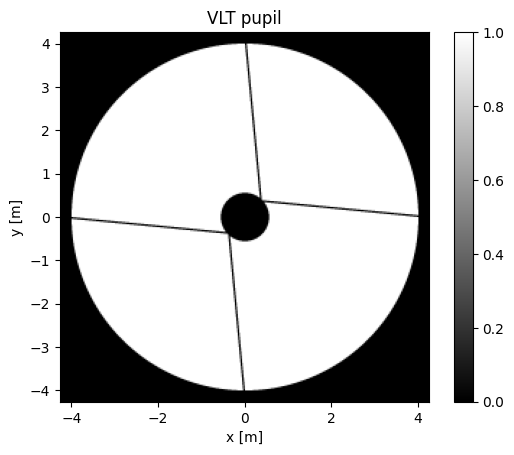

In [27]:
pupil_grid = make_pupil_grid(
    int(num_pupil_pixels * oversizing_factor), pupil_diameter * oversizing_factor
)
telescope_pupil = evaluate_supersampled(make_vlt_aperture(), pupil_grid, 4)
pupil_mask = telescope_pupil > 0.5  # boolean mask used for statistics and display
pupil_extent = pupil_grid.delta[0] * pupil_grid.shape[0] / 2 * np.array([-1, 1, -1, 1])


def masked(field_or_array):
    """Return a 2D array with NaN outside the pupil, for display."""
    arr = np.asarray(field_or_array).reshape(pupil_grid.shape).copy()
    arr[~pupil_mask.reshape(pupil_grid.shape)] = np.nan
    return arr


imshow_field(telescope_pupil, cmap="gray")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("VLT pupil")
plt.colorbar()
plt.show()

## 1. The atmosphere

A single frozen-flow phase screen, generated with the infinite phase-screen extrusion method and translated at the
wind speed. The strength is set by the seeing: 0.7" at 500 nm corresponds to a Fried parameter $r_0 \approx 14$ cm.
The phase screen is wavelength independent when expressed as an optical path difference (OPD, in nm), which is what
all wavefront movies show.

r0 = 14.4 cm at 500 nm, 21.6 cm at 700 nm, 85 cm at 2.2 um
D/r0 = 55 at 500 nm
coherence time tau0 = 3.4 ms at 700 nm,  loop period = 2 ms
atmosphere crosses one actuator pitch (0.33 m) in 16.7 ms


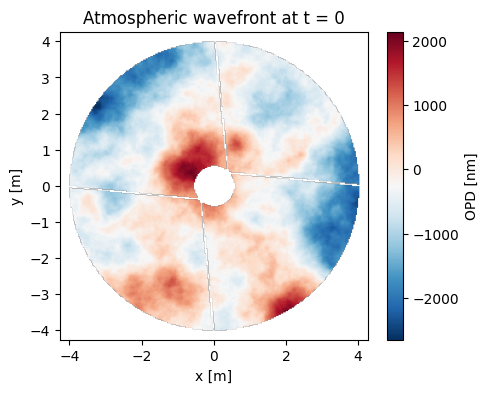

In [28]:
r0_500 = seeing_to_fried_parameter(seeing, 500e-9)
Cn_squared = Cn_squared_from_fried_parameter(r0_500, 500e-9)
layer = InfiniteAtmosphericLayer(
    pupil_grid, Cn_squared, outer_scale, wind_speed, seed=atmosphere_seed
)

r0_wfs = r0_500 * (wavelength_wfs / 500e-9) ** 1.2
r0_sci = r0_500 * (wavelength_sci / 500e-9) ** 1.2
tau0_wfs = 0.314 * r0_wfs / wind_speed
print(
    f"r0 = {r0_500*100:.1f} cm at 500 nm, {r0_wfs*100:.1f} cm at {wavelength_wfs*1e9:.0f} nm, {r0_sci*100:.0f} cm at {wavelength_sci*1e6:.1f} um"
)
print(f"D/r0 = {pupil_diameter/r0_500:.0f} at 500 nm")
print(
    f"coherence time tau0 = {tau0_wfs*1e3:.1f} ms at {wavelength_wfs*1e9:.0f} nm,  loop period = {1e3/loop_rate:.0f} ms"
)
print(
    f"atmosphere crosses one actuator pitch ({pupil_diameter/num_actuators_across:.2f} m) in {pupil_diameter/num_actuators_across/wind_speed*1e3:.1f} ms"
)


def opd_nm(phase, wavelength):
    """Phase [rad] at a wavelength to optical path difference [nm]."""
    return phase * wavelength / (2 * np.pi) * 1e9


plt.figure(figsize=(5, 4))
plt.imshow(
    masked(opd_nm(layer.phase_for(wavelength_sci), wavelength_sci)),
    cmap="RdBu_r",
    extent=pupil_extent,
)
plt.colorbar(label="OPD [nm]")
plt.title("Atmospheric wavefront at t = 0")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.show()

## 2. The pyramid wavefront sensor

The star light at 700 nm is focused on the tip of a four-sided glass pyramid. Each face sends the light to a different
pupil image on the detector, so a local wavefront slope changes the balance of light between the four pupils.
The sensor is modulated (the spot describes a circle of radius 5 $\lambda/D$ around the tip) to make its response
linear enough to close the loop on uncorrected turbulence.

Detector layout: 36 pixels across each pupil image, pupil images separated by 1.5 pupil diameters, so the detector has
$2 \times 1.5 \times 36 = 108$ pixels on a side.

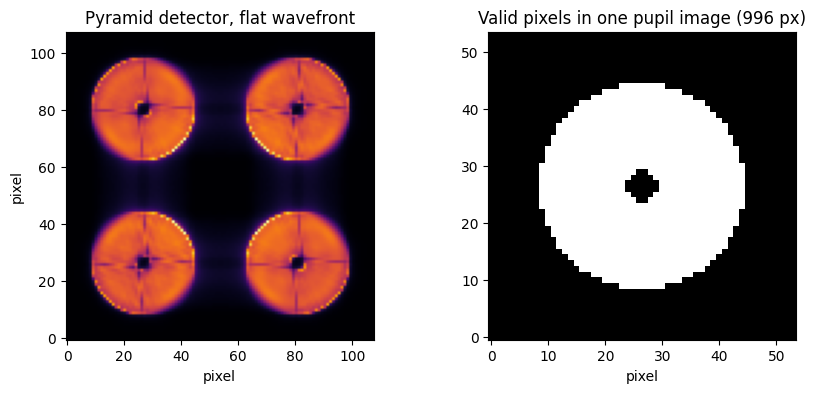

In [29]:
num_wfs_pixels = int(2 * wfs_pupil_separation * wfs_pixels_across_pupil)
wfs_pixel_size = pupil_diameter / wfs_pixels_across_pupil
pwfs_grid = make_pupil_grid(num_wfs_pixels, num_wfs_pixels * wfs_pixel_size)

pyramid = PyramidWavefrontSensorOptics(
    pupil_grid,
    pwfs_grid,
    separation=wfs_pupil_separation * pupil_diameter,
    pupil_diameter=pupil_diameter,
    wavelength_0=wavelength_wfs,
    num_airy=wfs_num_airy,
)
pwfs = ModulatedPyramidWavefrontSensorOptics(
    pyramid,
    modulation_radius * wavelength_wfs / pupil_diameter,
    modulation_steps,
    fast_modulation_method=True,
)
wfs_camera = NoisyDetector(pwfs_grid, include_photon_noise=True)

# Mask of valid pixels inside one pupil image (one quadrant of the detector).
num_quadrant = num_wfs_pixels // 2
quadrant_grid = make_pupil_grid(num_quadrant, num_quadrant * wfs_pixel_size)
quadrant_mask = (
    evaluate_supersampled(
        make_obstructed_circular_aperture(pupil_diameter, 0.15), quadrant_grid, 4
    )
    > 0.5
)
num_slopes = 2 * int(quadrant_mask.sum())


def wfs_image(wavefront, dt=None):
    """Pyramid detector image for a pupil-plane wavefront.

    With dt=None the image is noiseless and normalised to unit flux (used for calibration).
    With dt in seconds the image is integrated on the noisy detector for that time.
    """
    wf_modulated = pwfs(wavefront)
    if dt is None:
        image = sum(wf.power for wf in wf_modulated)
        return Field(image / image.sum(), pwfs_grid)
    for wf in wf_modulated:
        wfs_camera.integrate(wf, dt / len(wf_modulated))
    return wfs_camera.read_out()


def wfs_slopes(image):
    """Normalised x and y slopes from the four pupil images (HCIPy convention), restricted to the pupil mask."""
    img = image.shaped
    h = num_quadrant
    I_a = img[:h, :h]
    I_b = img[h:, :h]
    I_c = img[h:, h:]
    I_d = img[:h, h:]
    norm = I_a + I_b + I_c + I_d
    inv_norm = np.zeros_like(norm)
    inv_norm[norm > 0] = 1 / norm[norm > 0]
    s_x = ((I_a + I_b - I_c - I_d) * inv_norm).ravel()[quadrant_mask]
    s_y = ((I_a - I_b - I_c + I_d) * inv_norm).ravel()[quadrant_mask]
    return np.concatenate([s_x, s_y])


def slopes_to_maps(slopes):
    """Put a slopes vector back on the quadrant grid (NaN outside the pupil) for display."""
    maps = []
    for s in (slopes[: num_slopes // 2], slopes[num_slopes // 2 :]):
        m = np.full(quadrant_mask.size, np.nan)
        m[quadrant_mask] = s
        maps.append(m.reshape(quadrant_grid.shape))
    return maps


wf_flat = Wavefront(telescope_pupil, wavelength_wfs)
wf_flat.total_power = 1
reference_image = wfs_image(wf_flat)
reference_slopes = wfs_slopes(reference_image)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(reference_image.shaped, cmap="inferno")
axes[0].set_title("Pyramid detector, flat wavefront")
axes[0].set_xlabel("pixel")
axes[0].set_ylabel("pixel")
axes[1].imshow(quadrant_mask.reshape(quadrant_grid.shape), cmap="gray")
axes[1].set_title(f"Valid pixels in one pupil image ({num_slopes // 2} px)")
axes[1].set_xlabel("pixel")
plt.show()

## 3. The deformable mirror

A 24 x 24 grid of actuators with Gaussian influence functions (15% coupling between neighbours). Each actuator pushes
the mirror surface up or down; a wavefront reflecting off the mirror picks up twice the surface displacement as OPD.

576 actuators, pitch 33.3 cm, 464 controlled


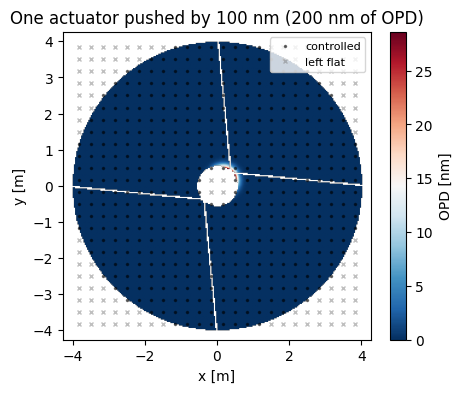

In [30]:
actuator_spacing = pupil_diameter / num_actuators_across
influence_functions = make_gaussian_influence_functions(
    pupil_grid, num_actuators_across, actuator_spacing, crosstalk=0.15
)
dm = DeformableMirror(influence_functions)
actuator_positions = make_actuator_positions(num_actuators_across, actuator_spacing)

# Actuators at the edge of the pupil or under the central obstruction are barely seen by the sensor and would run away
# in closed loop, so only the well illuminated ones are controlled; the others stay flat.
influence_weight = np.asarray(
    influence_functions.transformation_matrix.sum(axis=0)
).ravel()
illumination = (
    np.asarray(telescope_pupil @ influence_functions.transformation_matrix).ravel()
    / influence_weight
)
active_actuators = illumination > min_illumination
num_active = int(active_actuators.sum())
print(
    f"{dm.num_actuators} actuators, pitch {actuator_spacing*100:.1f} cm, {num_active} controlled"
)


def set_dm(commands):
    """Apply a command vector [m] for the active actuators; inactive actuators stay flat."""
    full = np.zeros(dm.num_actuators)
    full[active_actuators] = commands
    dm.actuators = full


# Show one poked actuator
dm.flatten()
dm.actuators[
    num_actuators_across * (num_actuators_across // 2) + num_actuators_across // 2
] = 100e-9
plt.figure(figsize=(5, 4))
plt.imshow(masked(dm.opd * 1e9), cmap="RdBu_r", extent=pupil_extent)
plt.plot(
    actuator_positions.x[active_actuators],
    actuator_positions.y[active_actuators],
    ".",
    color="k",
    ms=3,
    alpha=0.5,
    label="controlled",
)
plt.plot(
    actuator_positions.x[~active_actuators],
    actuator_positions.y[~active_actuators],
    "x",
    color="gray",
    ms=3,
    alpha=0.5,
    label="left flat",
)
plt.legend(loc="upper right", fontsize=8)
plt.colorbar(label="OPD [nm]")
plt.title("One actuator pushed by 100 nm (200 nm of OPD)")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.show()
dm.flatten()

### Calibration: interaction matrix and reconstructor

Every actuator is pushed and pulled in turn and the change of the WFS slopes is recorded. The (pseudo-)inverse of this
interaction matrix turns measured slopes into actuator commands.

interaction matrix measured in 8 s


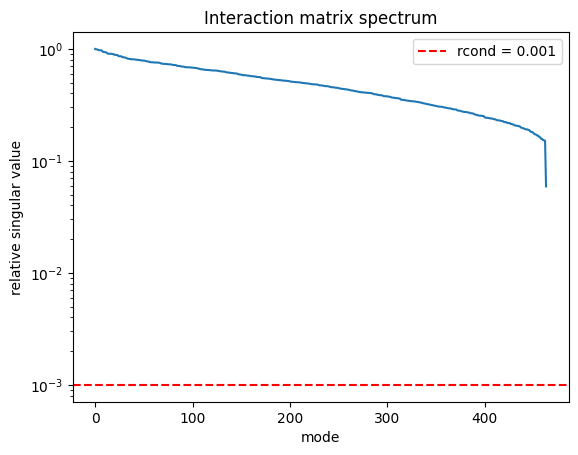

In [31]:
t0 = time.time()
interaction_matrix = np.zeros((num_slopes, num_active))
for i in range(num_active):
    response = 0
    for amplitude in (probe_amplitude, -probe_amplitude):
        commands = np.zeros(num_active)
        commands[i] = amplitude
        set_dm(commands)
        slopes = wfs_slopes(wfs_image(dm(wf_flat))) - reference_slopes
        response += slopes / (2 * amplitude)
    interaction_matrix[:, i] = response
dm.flatten()
print(f"interaction matrix measured in {time.time() - t0:.0f} s")

reconstruction_matrix = inverse_tikhonov(interaction_matrix, rcond=rcond)

singular_values = np.linalg.svd(interaction_matrix, compute_uv=False)
plt.semilogy(singular_values / singular_values[0])
plt.axhline(rcond, color="r", ls="--", label=f"rcond = {rcond}")
plt.xlabel("mode")
plt.ylabel("relative singular value")
plt.title("Interaction matrix spectrum")
plt.legend()
plt.show()

## 4. The science camera: Lyot coronagraph in the K band

An opaque focal-plane mask of radius 3 $\lambda/D$ blocks the core of the star and an undersized Lyot stop removes the
diffracted starlight at the edges of the pupil. Images are normalised to the peak of the non-coronagraphic star image
(same exposure, same Lyot stop), so the colour scale reads directly as raw contrast.

A second detector records the same light *without* the coronagraph (no focal-plane mask, no Lyot stop), i.e. what a
classical imaging camera would see behind the AO system. Those images are normalised to the peak of the perfect
non-coronagraphic PSF, so their peak value reads as the Strehl ratio.

5 AO steps per science exposure of 10 ms
star flux 4.27e+08 photons/s, 4.27e+06 photons per exposure


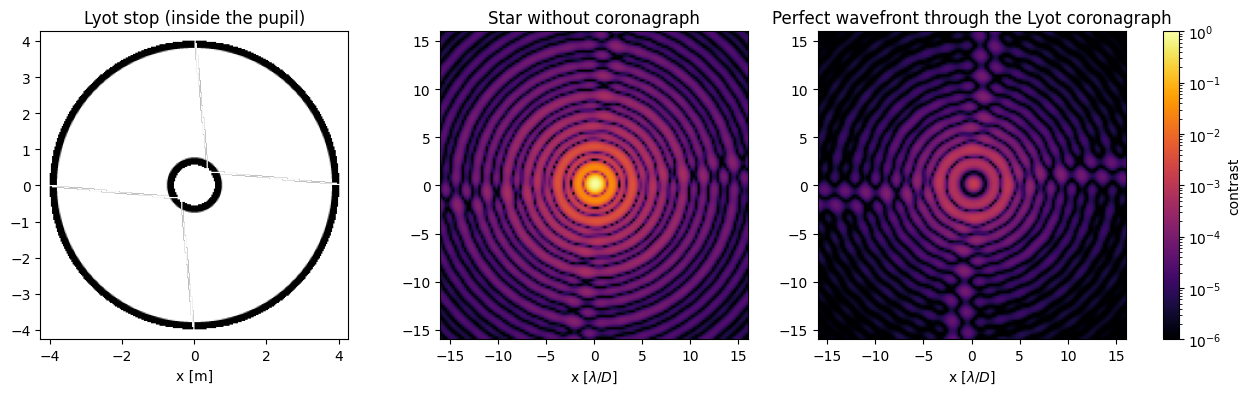

In [32]:
spatial_resolution_sci = wavelength_sci / pupil_diameter
focal_grid_sci = make_focal_grid(
    q_sci, num_airy_sci, spatial_resolution=spatial_resolution_sci
)
propagator_sci = FraunhoferPropagator(pupil_grid, focal_grid_sci)
sci_extent = num_airy_sci * np.array([-1, 1, -1, 1])

fpm_grid = make_focal_grid(
    q=8, num_airy=fpm_radius * 1.5, spatial_resolution=spatial_resolution_sci
)
focal_plane_mask = 1 - evaluate_supersampled(
    make_circular_aperture(2 * fpm_radius * spatial_resolution_sci), fpm_grid, 8
)
lyot_stop = evaluate_supersampled(
    make_obstructed_circular_aperture(
        lyot_undersize * pupil_diameter, lyot_obscuration
    ),
    pupil_grid,
    4,
)
coronagraph = LyotCoronagraph(pupil_grid, focal_plane_mask, lyot_stop)

sci_camera = NoisyDetector(
    focal_grid_sci, include_photon_noise=True
)  # behind the Lyot coronagraph
sci_camera_direct = NoisyDetector(
    focal_grid_sci, include_photon_noise=True
)  # no coronagraph at all
steps_per_dit = int(round(dit * loop_rate))
dt = 1 / loop_rate

# Reference: non-coronagraphic image of the star through the Lyot stop, for the same DIT, no noise.
wf_sci_flat = Wavefront(telescope_pupil, wavelength_sci)
wf_sci_flat.total_power = star_flux
psf_reference = propagator_sci(Apodizer(lyot_stop)(wf_sci_flat)).power * dit
peak_reference = psf_reference.max()
coro_perfect = propagator_sci(coronagraph(wf_sci_flat)).power * dit
# Reference for the non-coronagraphic camera: perfect PSF through the full telescope pupil (no Lyot stop), same DIT, no noise.
psf_direct = propagator_sci(wf_sci_flat).power * dit
peak_direct = psf_direct.max()

print(f"{steps_per_dit} AO steps per science exposure of {dit*1e3:.0f} ms")
print(f"star flux {star_flux:.2e} photons/s, {star_flux*dit:.2e} photons per exposure")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(masked(lyot_stop), cmap="gray", extent=pupil_extent)
axes[0].set_title("Lyot stop (inside the pupil)")
axes[0].set_xlabel("x [m]")
im = axes[1].imshow(
    psf_reference.shaped / peak_reference,
    norm=LogNorm(1e-6, 1),
    cmap="inferno",
    extent=sci_extent,
)
axes[1].set_title("Star without coronagraph")
axes[1].set_xlabel(r"x [$\lambda/D$]")
im = axes[2].imshow(
    coro_perfect.shaped / peak_reference,
    norm=LogNorm(1e-6, 1),
    cmap="inferno",
    extent=sci_extent,
)
axes[2].set_title("Perfect wavefront through the Lyot coronagraph")
axes[2].set_xlabel(r"x [$\lambda/D$]")
plt.colorbar(im, ax=axes[1:], label="contrast", fraction=0.03)
plt.show()

## 5. Run the closed loop

At every loop step (2 ms):

1. the atmosphere moves by `wind_speed / loop_rate` = 4 cm;
2. the 700 nm light goes atmosphere -> DM -> pyramid -> detector (photon noise included), slopes are computed;
3. the DM is updated with the slopes of the *previous* step (one frame of delay) through a leaky integrator;
4. the 2.2 um light goes atmosphere -> DM -> science camera, once directly (no coronagraph) and once through the Lyot
   coronagraph; both detectors are read out every 5 steps.

Everything needed for the movies is stored, so the movies can be re-rendered without re-running the loop. The wavefront
maps are stored with their mean over the pupil (piston) removed, since piston has no effect on the image.

In [33]:
num_steps = int(round(t_total * loop_rate))
num_exposures = num_steps // steps_per_dit
shape_pupil = pupil_grid.shape

atmosphere_opd = np.zeros((num_steps, *shape_pupil), dtype=np.float32)  # nm
dm_opd = np.zeros((num_steps, *shape_pupil), dtype=np.float32)  # nm
residual_opd = np.zeros((num_steps, *shape_pupil), dtype=np.float32)  # nm
wfs_images = np.zeros((num_steps, *pwfs_grid.shape), dtype=np.float32)
wfs_slopes_history = np.zeros((num_steps, num_slopes), dtype=np.float32)
actuator_history = np.zeros(
    (num_steps, dm.num_actuators), dtype=np.float32
)  # nm of surface
psf_uncorrected = np.zeros(
    (num_steps, *focal_grid_sci.shape), dtype=np.float32
)  # instantaneous, no AO, no coronagraph
science_frames = np.zeros(
    (num_exposures, *focal_grid_sci.shape), dtype=np.float32
)  # photons per DIT, Lyot coronagraph
science_frames_direct = np.zeros(
    (num_exposures, *focal_grid_sci.shape), dtype=np.float32
)  # photons per DIT, no coronagraph
residual_rms = np.zeros(num_steps)  # nm, over the pupil
strehl_sci = np.zeros(num_steps)

wf_wfs = Wavefront(telescope_pupil, wavelength_wfs)
wf_wfs.total_power = star_flux
wf_sci = Wavefront(telescope_pupil, wavelength_sci)
wf_sci.total_power = star_flux

layer.reset()
dm.flatten()
commands = np.zeros(num_active)  # DM surface commands of the active actuators [m]
previous_slopes = None
t0 = time.time()
for i in range(num_steps):
    layer.evolve_until(i * dt)

    # --- wavefront sensing at 700 nm
    wf_after_dm = dm(layer(wf_wfs))
    image = wfs_image(wf_after_dm, dt)
    slopes = wfs_slopes(image) - reference_slopes

    # --- control: apply the previous measurement (one frame delay)
    if previous_slopes is not None:
        commands = (1 - leakage) * commands - gain * reconstruction_matrix.dot(
            previous_slopes
        )
        set_dm(commands)
    previous_slopes = slopes

    # --- science channel at 2.2 um
    wf_sci_atm = layer(wf_sci)
    wf_sci_corrected = dm(wf_sci_atm)
    sci_camera.integrate(propagator_sci(coronagraph(wf_sci_corrected)), dt)
    sci_camera_direct.integrate(propagator_sci(wf_sci_corrected), dt)
    if (i + 1) % steps_per_dit == 0:
        science_frames[(i + 1) // steps_per_dit - 1] = sci_camera.read_out().shaped
        science_frames_direct[(i + 1) // steps_per_dit - 1] = (
            sci_camera_direct.read_out().shaped
        )

    # --- bookkeeping
    atm = opd_nm(layer.phase_for(wavelength_sci), wavelength_sci)
    atm -= atm[pupil_mask].mean()  # piston does not matter: remove it over the pupil
    mirror = dm.opd * 1e9
    mirror -= mirror[pupil_mask].mean()
    residual = atm + mirror
    atmosphere_opd[i] = atm.shaped
    dm_opd[i] = mirror.shaped
    residual_opd[i] = residual.shaped
    wfs_images[i] = image.shaped
    wfs_slopes_history[i] = slopes
    actuator_history[i] = dm.actuators * 1e9
    psf_uncorrected[i] = propagator_sci(wf_sci_atm).power.shaped
    res_in_pupil = residual[pupil_mask]
    residual_rms[i] = np.std(res_in_pupil)
    strehl_sci[i] = np.exp(
        -((2 * np.pi * residual_rms[i] * 1e-9 / wavelength_sci) ** 2)
    )

    if (i + 1) % 50 == 0:
        print(
            f"step {i+1:4d}/{num_steps}  t = {(i+1)*dt*1e3:6.1f} ms  residual rms = {residual_rms[i]:6.0f} nm  Strehl(K) = {strehl_sci[i]:.2f}  ({time.time()-t0:.0f} s)"
        )

time_ms = np.arange(num_steps) * dt * 1e3
atmosphere_rms = atmosphere_opd[:, pupil_mask.reshape(shape_pupil)].std(axis=1)

step   50/500  t =  100.0 ms  residual rms =    166 nm  Strehl(K) = 0.80  (5 s)
step  100/500  t =  200.0 ms  residual rms =    164 nm  Strehl(K) = 0.80  (10 s)
step  150/500  t =  300.0 ms  residual rms =    158 nm  Strehl(K) = 0.82  (15 s)
step  200/500  t =  400.0 ms  residual rms =    174 nm  Strehl(K) = 0.78  (19 s)
step  250/500  t =  500.0 ms  residual rms =    171 nm  Strehl(K) = 0.79  (24 s)
step  300/500  t =  600.0 ms  residual rms =    148 nm  Strehl(K) = 0.84  (29 s)
step  350/500  t =  700.0 ms  residual rms =    202 nm  Strehl(K) = 0.72  (33 s)
step  400/500  t =  800.0 ms  residual rms =    238 nm  Strehl(K) = 0.63  (38 s)
step  450/500  t =  900.0 ms  residual rms =    214 nm  Strehl(K) = 0.69  (43 s)
step  500/500  t = 1000.0 ms  residual rms =    195 nm  Strehl(K) = 0.73  (47 s)


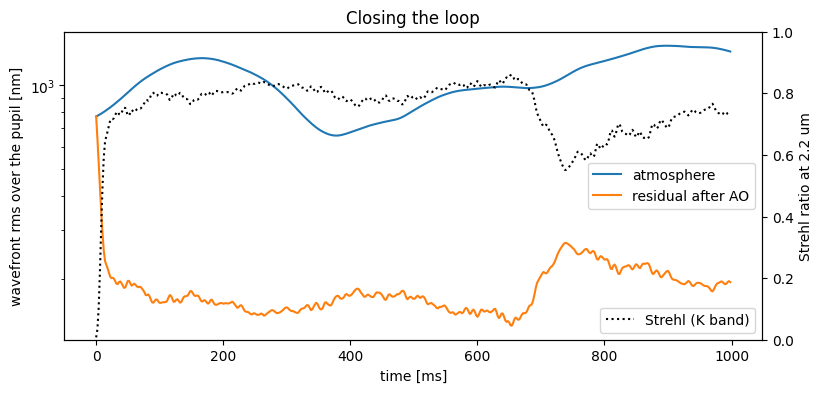

after convergence: residual rms = 194 nm, Strehl(K) = 0.73


In [34]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(time_ms, atmosphere_rms, label="atmosphere")
ax1.plot(time_ms, residual_rms, label="residual after AO")
ax1.set_yscale("log")
ax1.set_xlabel("time [ms]")
ax1.set_ylabel("wavefront rms over the pupil [nm]")
ax1.legend(loc="center right")
ax2 = ax1.twinx()
ax2.plot(time_ms, strehl_sci, color="k", ls=":", label="Strehl (K band)")
ax2.set_ylabel("Strehl ratio at 2.2 um")
ax2.set_ylim(0, 1)
ax2.legend(loc="lower right")
plt.title("Closing the loop")
plt.show()
converged = slice(num_steps // 2, None)
print(
    f"after convergence: residual rms = {residual_rms[converged].mean():.0f} nm, Strehl(K) = {strehl_sci[converged].mean():.2f}"
)

## Movies

A small helper renders one Matplotlib figure per frame and streams it to HCIPy's `FFMpegWriter`. Each movie is also
saved as a PNG of its last frame so the notebook shows something even without video playback.

In [42]:
def render_movie(name, frames, setup, update, fps, figsize):
    """Render a movie.

    setup(fig) -> state, called once; update(state, i) updates the artists for AO step i.
    """
    path = out_dir / f"{name}.mp4"
    fig = plt.figure(figsize=figsize)
    state = setup(fig)
    writer = FFMpegWriter(str(path), framerate=fps)
    t0 = time.time()
    fig.savefig(out_dir / f"{name}_first_frame.png", dpi=movie_dpi)
    for i in frames:
        update(state, i)
        writer.add_frame(fig, dpi=movie_dpi)
    writer.close()
    fig.savefig(out_dir / f"{name}_last_frame.png", dpi=movie_dpi)
    plt.close(fig)
    print(
        f"{path}  ({len(frames)} frames, {os.path.getsize(path)/1e6:.1f} MB, rendered in {time.time()-t0:.0f} s)"
    )
    return path


def show_movie(path):
    display(Video(str(path), embed=False, width=800))


step_frames = np.arange(0, num_steps, movie_every)
wfs_display_scale = (
    3
    * wfs_images[
        :, wfs_images.mean(axis=0) > 0.2 * wfs_images.mean(axis=0).max()
    ].mean()
)  # 3 x mean illuminated pixel
exposure_frames = np.arange(num_exposures)
slow_motion = movie_fps / loop_rate


def time_label(i):
    return f"t = {time_ms[i]:6.1f} ms   (loop step {i+1}/{num_steps})"


def symmetric_scale(data, percentile=99.5, step=50):
    v = np.nanpercentile(np.abs(data), percentile)
    return float(np.ceil(v / step) * step)


atmosphere_scale = symmetric_scale(atmosphere_opd[:, pupil_mask.reshape(shape_pupil)])
residual_scale = float(
    np.ceil(4 * residual_rms[converged].mean() / 50) * 50
)  # 4 x rms; a few uncorrected edge pixels exceed it
print(
    f"colour scales: atmosphere +/-{atmosphere_scale:.0f} nm, residual +/-{residual_scale:.0f} nm"
)

colour scales: atmosphere +/-2900 nm, residual +/-800 nm


### Movie 1: the distorted wavefront

Left: the atmospheric OPD across the pupil, blown across the telescope by the wind. Right: the K band image a camera
would record *without* AO (instantaneous, no coronagraph). The image breaks up into speckles and dances around.

In [43]:
def setup_atmosphere(fig):
    ax1, ax2 = fig.subplots(1, 2)
    im1 = ax1.imshow(
        masked(atmosphere_opd[0]),
        cmap="RdBu_r",
        vmin=-atmosphere_scale,
        vmax=atmosphere_scale,
        extent=pupil_extent,
    )
    ax1.set_title("Wavefront after the atmosphere")
    ax1.set_xlabel("x [m]")
    ax1.set_ylabel("y [m]")
    fig.colorbar(im1, ax=ax1, label="optical path difference [nm]", fraction=0.046)
    ax1.annotate(
        "", xy=(3.2, -3.6), xytext=(1.2, -3.6), arrowprops=dict(arrowstyle="->", lw=2)
    )
    ax1.text(2.2, -3.95, f"wind {wind_speed:.0f} m/s", ha="center", fontsize=9)
    im2 = ax2.imshow(
        psf_uncorrected[0] / psf_uncorrected[0].max(),
        norm=LogNorm(1e-4, 1),
        cmap="inferno",
        extent=sci_extent,
    )
    ax2.set_title("Star image without AO (2.2 um)")
    ax2.set_xlabel(r"x [$\lambda/D$]")
    ax2.set_ylabel(r"y [$\lambda/D$]")
    fig.colorbar(im2, ax=ax2, label="normalised intensity", fraction=0.046)
    title = fig.suptitle("", fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    return im1, im2, title


def update_atmosphere(state, i):
    im1, im2, title = state
    im1.set_data(masked(atmosphere_opd[i]))
    im2.set_data(psf_uncorrected[i] / psf_uncorrected[i].max())
    title.set_text(
        f'Seeing {seeing}" at 500 nm, wavefront rms {atmosphere_rms[i]:.0f} nm   |   {time_label(i)}'
    )


movie_atmosphere = render_movie(
    "1_distorted_wavefront",
    step_frames,
    setup_atmosphere,
    update_atmosphere,
    movie_fps,
    (11, 4.8),
)
show_movie(movie_atmosphere)

results/animations/ao_explainer/1_distorted_wavefront.mp4  (500 frames, 13.1 MB, rendered in 75 s)


### Movie 2: the wavefront sensor

Left: the pyramid detector (four images of the pupil). Where the wavefront is tilted locally, light moves from one
pupil image to another. Middle and right: the x and y slope maps computed from the four images; these are the numbers
the real-time computer works with. The pattern becomes flat and noisy once the loop has closed.

In [44]:
def setup_wfs(fig):
    ax1, ax2, ax3 = fig.subplots(1, 3)
    im1 = ax1.imshow(wfs_images[0], cmap="inferno", vmin=0, vmax=wfs_display_scale)
    ax1.set_title("Pyramid detector (700 nm)")
    ax1.set_xlabel("pixel")
    ax1.set_ylabel("pixel")
    fig.colorbar(im1, ax=ax1, label="photons per pixel", fraction=0.046)
    sx, sy = slopes_to_maps(wfs_slopes_history[0])
    slope_scale = np.nanpercentile(np.abs(wfs_slopes_history), 99)
    im2 = ax2.imshow(sx, cmap="RdBu_r", vmin=-slope_scale, vmax=slope_scale)
    ax2.set_title("x slopes")
    ax2.set_xlabel("pixel")
    im3 = ax3.imshow(sy, cmap="RdBu_r", vmin=-slope_scale, vmax=slope_scale)
    ax3.set_title("y slopes")
    ax3.set_xlabel("pixel")
    fig.colorbar(im3, ax=[ax2, ax3], label="normalised slope", fraction=0.023)
    title = fig.suptitle("", fontsize=12, y=0.97)
    return im1, im2, im3, title


def update_wfs(state, i):
    im1, im2, im3, title = state
    im1.set_data(wfs_images[i])
    sx, sy = slopes_to_maps(wfs_slopes_history[i])
    im2.set_data(sx)
    im3.set_data(sy)
    title.set_text(
        f"Pyramid wavefront sensor, {wfs_pixels_across_pupil} px across the pupil, {np.sum(wfs_images[i]):.1e} photons   |   {time_label(i)}"
    )


movie_wfs = render_movie(
    "2_wavefront_sensor", step_frames, setup_wfs, update_wfs, movie_fps, (15, 4.8)
)
show_movie(movie_wfs)

results/animations/ao_explainer/2_wavefront_sensor.mp4  (500 frames, 21.1 MB, rendered in 36 s)


### Movie 3: the deformable mirror

Left: the shape of the deformable mirror as OPD (twice its surface), with the actuator grid overlaid. Right: the
command sent to each of the 24 x 24 actuators. Compare with movie 1: the mirror takes the *opposite* shape of the
atmosphere, as far as the actuator grid allows.

In [45]:
def actuator_map(i):
    """Actuator commands on the 24 x 24 grid, NaN for the actuators that are not controlled."""
    m = actuator_history[i].copy()
    m[~active_actuators] = np.nan
    return m.reshape(num_actuators_across, num_actuators_across)


def setup_dm(fig):
    ax1, ax2 = fig.subplots(1, 2)
    im1 = ax1.imshow(
        masked(dm_opd[0]),
        cmap="RdBu_r",
        vmin=-atmosphere_scale,
        vmax=atmosphere_scale,
        extent=pupil_extent,
    )
    ax1.plot(
        actuator_positions.x, actuator_positions.y, ".", color="k", ms=2, alpha=0.3
    )
    ax1.set_title("Deformable mirror shape (as OPD)")
    ax1.set_xlabel("x [m]")
    ax1.set_ylabel("y [m]")
    fig.colorbar(im1, ax=ax1, label="optical path difference [nm]", fraction=0.046)
    im2 = ax2.imshow(
        actuator_map(0),
        cmap="RdBu_r",
        vmin=-atmosphere_scale / 2,
        vmax=atmosphere_scale / 2,
    )
    ax2.set_title(
        f"Actuator commands ({num_actuators_across} x {num_actuators_across})"
    )
    ax2.set_xlabel("actuator column")
    ax2.set_ylabel("actuator row")
    fig.colorbar(im2, ax=ax2, label="surface stroke [nm]", fraction=0.046)
    title = fig.suptitle("", fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    return im1, im2, title


def update_dm(state, i):
    im1, im2, title = state
    im1.set_data(masked(dm_opd[i]))
    im2.set_data(actuator_map(i))
    title.set_text(
        f"Deformable mirror, loop at {loop_rate:.0f} Hz, gain {gain}   |   {time_label(i)}"
    )


movie_dm = render_movie(
    "3_deformable_mirror", step_frames, setup_dm, update_dm, movie_fps, (11, 4.8)
)
show_movie(movie_dm)

results/animations/ao_explainer/3_deformable_mirror.mp4  (500 frames, 6.9 MB, rendered in 47 s)


### Movie 4: the corrected wavefront

Left: atmosphere plus mirror, i.e. what reaches the science camera. Note the colour scale, which is much tighter than
in movie 1. Right: the residual rms and the resulting K band Strehl ratio as a function of time.

In [46]:
def setup_residual(fig):
    ax1, ax2 = fig.subplots(1, 2, gridspec_kw={"width_ratios": [1, 1.3]})
    im1 = ax1.imshow(
        masked(residual_opd[0]),
        cmap="RdBu_r",
        vmin=-residual_scale,
        vmax=residual_scale,
        extent=pupil_extent,
    )
    ax1.set_title("Residual wavefront (atmosphere + DM)")
    ax1.set_xlabel("x [m]")
    ax1.set_ylabel("y [m]")
    fig.colorbar(im1, ax=ax1, label="optical path difference [nm]", fraction=0.046)
    ax2.plot(time_ms, atmosphere_rms, color="C0", label="atmosphere")
    ax2.plot(time_ms, residual_rms, color="C1", label="residual")
    ax2.set_yscale("log")
    ax2.set_xlim(0, time_ms[-1])
    ax2.set_xlabel("time [ms]")
    ax2.set_ylabel("wavefront rms [nm]")
    ax2.legend(loc="upper right")
    cursor = ax2.axvline(0, color="k", lw=1)
    (marker,) = ax2.plot([0], [residual_rms[0]], "o", color="C1")
    title = fig.suptitle("", fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    return im1, cursor, marker, title


def update_residual(state, i):
    im1, cursor, marker, title = state
    im1.set_data(masked(residual_opd[i]))
    cursor.set_xdata([time_ms[i], time_ms[i]])
    marker.set_data([time_ms[i]], [residual_rms[i]])
    title.set_text(
        f"Residual rms {residual_rms[i]:.0f} nm, Strehl(K) = {strehl_sci[i]:.2f}   |   {time_label(i)}"
    )


movie_residual = render_movie(
    "4_corrected_wavefront",
    step_frames,
    setup_residual,
    update_residual,
    movie_fps,
    (12, 4.8),
)
show_movie(movie_residual)

results/animations/ao_explainer/4_corrected_wavefront.mp4  (500 frames, 10.0 MB, rendered in 44 s)


### Movie 5: the science camera

Left: one 10 ms exposure of the coronagraphic camera (5 AO steps, photon noise included). Right: the average of all
exposures so far, i.e. the long exposure building up and the speckles smoothing out. Both are in units of raw contrast with respect to the peak of the
non-coronagraphic star image. The movie runs at the same slow-motion factor as the others, one frame per exposure.

In [47]:
cumulative = np.cumsum(science_frames, axis=0)
cumulative_direct = np.cumsum(science_frames_direct, axis=0)
exposure_time_ms = (exposure_frames + 1) * dit * 1e3
contrast_floor = 1e-6


def setup_science(fig):
    ax1, ax2 = fig.subplots(1, 2)
    im1 = ax1.imshow(
        np.maximum(science_frames[0] / peak_reference, contrast_floor),
        norm=LogNorm(1e-5, 1e-1),
        cmap="inferno",
        extent=sci_extent,
    )
    ax1.set_title(f"Single exposure, DIT = {dit*1e3:.0f} ms")
    ax1.set_xlabel(r"x [$\lambda/D$]")
    ax1.set_ylabel(r"y [$\lambda/D$]")
    im2 = ax2.imshow(
        np.maximum(cumulative[0] / peak_reference, contrast_floor),
        norm=LogNorm(1e-5, 1e-1),
        cmap="inferno",
        extent=sci_extent,
    )
    ax2.set_title("Average of all exposures so far (long exposure)")
    ax2.set_xlabel(r"x [$\lambda/D$]")
    fig.colorbar(
        im2, ax=[ax1, ax2], label="raw contrast (per exposure peak)", fraction=0.023
    )
    for ax in (ax1, ax2):
        ax.add_patch(
            plt.Circle((0, 0), fpm_radius, fill=False, ls="--", color="w", lw=0.8)
        )
    title = fig.suptitle("", fontsize=12)
    return im1, im2, title


def update_science(state, k):
    im1, im2, title = state
    im1.set_data(np.maximum(science_frames[k] / peak_reference, contrast_floor))
    im2.set_data(np.maximum(cumulative[k] / ((k + 1) * peak_reference), contrast_floor))
    title.set_text(
        f"Lyot coronagraph, 2.2 um, {fpm_radius:.0f} lambda/D mask   |   exposure {k+1}/{num_exposures}, t = {exposure_time_ms[k]:.0f} ms"
    )


movie_science = render_movie(
    "5_science_camera",
    exposure_frames,
    setup_science,
    update_science,
    max(1, movie_fps // steps_per_dit),
    (11, 4.8),
)
show_movie(movie_science)

results/animations/ao_explainer/5_science_camera.mp4  (100 frames, 7.3 MB, rendered in 13 s)


### Bonus: everything on one screen

The same data arranged as a dashboard, handy for a talk. Top row: atmosphere, sensor, mirror, residual. Bottom row:
the science camera without coronagraph (last exposure and long exposure, normalised so that the peak reads as the
Strehl ratio) and the same behind the Lyot coronagraph (in raw contrast). The atmosphere panel shows the whole phase
screen on the simulation grid, not only the part inside the telescope pupil.

In [48]:
def last_exposure(i):
    return max(
        0, (i + 1) // steps_per_dit - 1
    )  # last completed science exposure at AO step i


def direct_exposure(i):
    return np.maximum(
        science_frames_direct[last_exposure(i)] / peak_direct, contrast_floor
    )


def direct_long_exposure(i):
    k = last_exposure(i)
    return np.maximum(cumulative_direct[k] / ((k + 1) * peak_direct), contrast_floor)


def coro_exposure(i):
    return np.maximum(science_frames[last_exposure(i)] / peak_reference, contrast_floor)


def coro_long_exposure(i):
    k = last_exposure(i)
    return np.maximum(cumulative[k] / ((k + 1) * peak_reference), contrast_floor)


opd_kwargs = dict(
    cmap="RdBu_r", vmin=-atmosphere_scale, vmax=atmosphere_scale, extent=pupil_extent
)
direct_kwargs = dict(norm=LogNorm(1e-5, 1), cmap="inferno", extent=sci_extent)
coro_kwargs = dict(norm=LogNorm(1e-5, 1e-1), cmap="inferno", extent=sci_extent)


def setup_dashboard(fig):
    axes = fig.subplots(2, 4)
    (ax_atm, ax_wfs, ax_dm, ax_res), (ax_dir, ax_dir_cum, ax_sci, ax_cum) = axes
    im_atm = ax_atm.imshow(
        atmosphere_opd[0], **opd_kwargs
    )  # full phase screen, not masked by the pupil
    ax_atm.set_title("1. Atmosphere [nm]")
    fig.colorbar(im_atm, ax=ax_atm, fraction=0.046)
    im_wfs = ax_wfs.imshow(
        wfs_images[0], cmap="inferno", vmin=0, vmax=wfs_display_scale
    )
    ax_wfs.set_title("2. Pyramid sensor")
    im_dm = ax_dm.imshow(masked(dm_opd[0]), **opd_kwargs)
    ax_dm.set_title("3. Deformable mirror [nm]")
    fig.colorbar(im_dm, ax=ax_dm, fraction=0.046)
    im_res = ax_res.imshow(
        masked(residual_opd[0]),
        cmap="RdBu_r",
        vmin=-residual_scale,
        vmax=residual_scale,
        extent=pupil_extent,
    )
    ax_res.set_title("4. Residual [nm]")
    fig.colorbar(im_res, ax=ax_res, fraction=0.046)
    im_dir = ax_dir.imshow(direct_exposure(0), **direct_kwargs)
    ax_dir.set_title(f"5. No coronagraph, last {dit*1e3:.0f} ms exposure")
    im_dir_cum = ax_dir_cum.imshow(direct_long_exposure(0), **direct_kwargs)
    ax_dir_cum.set_title("5. No coronagraph, long exposure")
    fig.colorbar(
        im_dir_cum,
        ax=[ax_dir, ax_dir_cum],
        label="normalised intensity",
        fraction=0.023,
    )
    im_sci = ax_sci.imshow(coro_exposure(0), **coro_kwargs)
    ax_sci.set_title(f"5. Coronagraph, last {dit*1e3:.0f} ms exposure")
    im_cum = ax_cum.imshow(coro_long_exposure(0), **coro_kwargs)
    ax_cum.set_title("5. Coronagraph, long exposure")
    fig.colorbar(im_cum, ax=[ax_sci, ax_cum], label="contrast", fraction=0.023)
    for ax in (ax_sci, ax_cum):
        ax.add_patch(
            plt.Circle((0, 0), fpm_radius, fill=False, ls="--", color="w", lw=0.8)
        )
    for ax in axes.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
    title = fig.suptitle("", fontsize=13)
    return im_atm, im_wfs, im_dm, im_res, im_dir, im_dir_cum, im_sci, im_cum, title


def update_dashboard(state, i):
    im_atm, im_wfs, im_dm, im_res, im_dir, im_dir_cum, im_sci, im_cum, title = state
    im_atm.set_data(atmosphere_opd[i])
    im_wfs.set_data(wfs_images[i])
    im_dm.set_data(masked(dm_opd[i]))
    im_res.set_data(masked(residual_opd[i]))
    im_dir.set_data(direct_exposure(i))
    im_dir_cum.set_data(direct_long_exposure(i))
    im_sci.set_data(coro_exposure(i))
    im_cum.set_data(coro_long_exposure(i))
    title.set_text(
        f"Adaptive optics at {loop_rate:.0f} Hz, residual {residual_rms[i]:.0f} nm rms, Strehl(K) {strehl_sci[i]:.2f}   |   {time_label(i)}"
    )


movie_dashboard = render_movie(
    "6_dashboard", step_frames, setup_dashboard, update_dashboard, movie_fps, (18, 8.5)
)
show_movie(movie_dashboard)

# Each dashboard panel as its own movie: no title, no colorbar, no axes, image filling the frame.
# The residual uses the same +/- atmosphere_scale colour scale as the atmosphere and DM panels.
panel_specs = {
    "6a_atmosphere": (lambda i: atmosphere_opd[i], opd_kwargs),  # full phase screen
    "6b_pyramid_sensor": (
        lambda i: wfs_images[i],
        dict(cmap="inferno", vmin=0, vmax=wfs_display_scale),
    ),
    "6c_deformable_mirror": (lambda i: masked(dm_opd[i]), opd_kwargs),
    "6d_residual": (lambda i: masked(residual_opd[i]), opd_kwargs),
    "6e_science_direct_exposure": (direct_exposure, direct_kwargs),
    "6f_science_direct_long_exposure": (direct_long_exposure, direct_kwargs),
    "6g_science_coronagraph_exposure": (coro_exposure, coro_kwargs),
    "6h_science_coronagraph_long_exposure": (coro_long_exposure, coro_kwargs),
}


def make_panel_setup(frame, kwargs):
    def setup(fig):
        ax = fig.add_axes([0, 0, 1, 1])
        ax.set_axis_off()
        return ax.imshow(frame(0), **kwargs)

    return setup


def make_panel_update(frame):
    def update(im, i):
        im.set_data(frame(i))

    return update


panel_movies = {}
for name, (frame, kwargs) in panel_specs.items():
    panel_movies[name] = render_movie(
        name,
        step_frames,
        make_panel_setup(frame, kwargs),
        make_panel_update(frame),
        movie_fps,
        (5, 5),
    )

results/animations/ao_explainer/6_dashboard.mp4  (500 frames, 28.6 MB, rendered in 125 s)


results/animations/ao_explainer/6a_atmosphere.mp4  (500 frames, 6.7 MB, rendered in 50 s)
results/animations/ao_explainer/6b_pyramid_sensor.mp4  (500 frames, 20.3 MB, rendered in 4 s)
results/animations/ao_explainer/6c_deformable_mirror.mp4  (500 frames, 3.5 MB, rendered in 27 s)
results/animations/ao_explainer/6d_residual.mp4  (500 frames, 5.4 MB, rendered in 32 s)
results/animations/ao_explainer/6e_science_direct_exposure.mp4  (500 frames, 9.3 MB, rendered in 5 s)
results/animations/ao_explainer/6f_science_direct_long_exposure.mp4  (500 frames, 2.9 MB, rendered in 5 s)
results/animations/ao_explainer/6g_science_coronagraph_exposure.mp4  (500 frames, 10.2 MB, rendered in 5 s)
results/animations/ao_explainer/6h_science_coronagraph_long_exposure.mp4  (500 frames, 3.2 MB, rendered in 5 s)


## Summary

The movies are in `results/animations/ao_explainer/`:

| file | shows | real time per movie second |
|---|---|---|
| `1_distorted_wavefront.mp4` | atmosphere OPD and the uncorrected K band image | 40 ms |
| `2_wavefront_sensor.mp4` | pyramid detector and slope maps | 40 ms |
| `3_deformable_mirror.mp4` | DM shape and actuator commands | 40 ms |
| `4_corrected_wavefront.mp4` | residual OPD and rms versus time | 40 ms |
| `5_science_camera.mp4` | 10 ms coronagraphic exposures and the long exposure | 40 ms |
| `6_dashboard.mp4` | all of the above, plus the science image without coronagraph (single and long exposure); atmosphere on the full grid | 40 ms |
| `6a_atmosphere.mp4` ... `6h_science_coronagraph_long_exposure.mp4` | each dashboard panel on its own, no title, colorbar or axes; residual on the atmosphere colour scale | 40 ms |

To change the story, edit the parameter cell (seeing, wind, loop rate, DIT, actuator count, pyramid sampling) and run
everything again. The loop cell stores all intermediate data, so the movie cells can be edited and re-run on their own.

In [ ]:
print(
    f"simulated {t_total:.1f} s of AO at {loop_rate:.0f} Hz, {num_exposures} science exposures of {dit*1e3:.0f} ms"
)
print(
    f"atmosphere rms {atmosphere_rms.mean():.0f} nm  ->  residual rms {residual_rms[converged].mean():.0f} nm, Strehl(K) {strehl_sci[converged].mean():.2f}"
)
for p in sorted(out_dir.glob("*.mp4")):
    print(p, f"{os.path.getsize(p)/1e6:.1f} MB")

simulated 1.0 s of AO at 500 Hz, 100 science exposures of 10 ms
atmosphere rms 1041 nm  ->  residual rms 194 nm, Strehl(K) 0.73
results/animations/ao_explainer/1_distorted_wavefront.mp4 13.1 MB
results/animations/ao_explainer/2_wavefront_sensor.mp4 21.1 MB
results/animations/ao_explainer/3_deformable_mirror.mp4 6.9 MB
results/animations/ao_explainer/4_corrected_wavefront.mp4 10.1 MB
results/animations/ao_explainer/5_science_camera.mp4 7.3 MB
results/animations/ao_explainer/6_dashboard.mp4 26.3 MB
results/animations/ao_explainer/6a_atmosphere.mp4 5.2 MB
results/animations/ao_explainer/6b_pyramid_sensor.mp4 20.4 MB
results/animations/ao_explainer/6c_deformable_mirror.mp4 3.5 MB
results/animations/ao_explainer/6d_residual.mp4 5.4 MB
results/animations/ao_explainer/6e_science_exposure.mp4 10.2 MB
results/animations/ao_explainer/6f_science_long_exposure.mp4 3.2 MB
